# Can Saliency Maps Flag Chest Radiograph Classifier Errors at a New Hospital? An External Validation Study
## ViT Training
## Aashish Chapagai (Last Edited: October 2026)

In [1]:
import os

os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import json
import tensorflow as tf
import keras_hub
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, auc
from sklearn.metrics import classification_report, multilabel_confusion_matrix
from sklearn.model_selection import GroupShuffleSplit

tf.get_logger().setLevel('ERROR')

os.makedirs('models', exist_ok=True)
os.makedirs('figures', exist_ok=True)

In [2]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_memory_growth(gpus[0], True)
    tf.keras.mixed_precision.set_global_policy('mixed_bfloat16')
    print(f"Training on {gpus[0].name} with mixed bfloat16 precision.")

Training on /physical_device:GPU:0 with mixed bfloat16 precision.


In [3]:
X_train = np.load('models/X_train.npy', mmap_mode='r')
X_test = np.load('models/X_test.npy', mmap_mode='r')
Y_train = np.load('models/Y_train.npy')
Y_test = np.load('models/Y_test.npy')
disease_classes = np.load('models/disease_classes.npy').tolist()
train_patient_ids = np.load('models/train_patient_ids.npy', allow_pickle=True)
test_patient_ids = np.load('models/test_patient_ids.npy', allow_pickle=True)

IMG_SIZE = X_train.shape[1]
BATCH_SIZE = 8
EVAL_BATCH_SIZE = 64
EPOCHS = 12
SEED = 42
VAL_FRACTION = 0.15
WARMUP_EPOCHS = 2
POS_WEIGHT_CAP = 8.0
HEAD_LR = 1e-3
WEIGHT_DECAY = 0.05
EMA_MOMENTUM = 0.999
DROPOUT = 0.5
BACKBONE_LR = float(5e-5 * np.sqrt(BATCH_SIZE / 32))
N_BOOTSTRAP = 1000
VIT_PRESET = 'vit_base_patch16_384_imagenet'
tf.keras.utils.set_random_seed(SEED)

print(f"Loaded {X_train.shape[0]} training and {X_test.shape[0]} test images at {IMG_SIZE}px ({X_train.dtype}).")
print(f"Predicting {len(disease_classes)} disease classes.")

shared_patients = set(train_patient_ids).intersection(test_patient_ids)
print(f"Patients appearing in both train and test: {len(shared_patients)}")

Loaded 90286 training and 21834 test images at 320px (uint8).
Predicting 14 disease classes.
Patients appearing in both train and test: 0


In [4]:
gss_val = GroupShuffleSplit(n_splits=1, test_size=VAL_FRACTION, random_state=SEED)
tr_sub_idx, val_sub_idx = next(gss_val.split(np.zeros(len(Y_train)), Y_train, groups=train_patient_ids))

tr_sub_idx = np.sort(tr_sub_idx)
val_sub_idx = np.sort(val_sub_idx)
Y_tr, Y_val = Y_train[tr_sub_idx], Y_train[val_sub_idx]
print(f"Training on {len(tr_sub_idx)} images, validating on {len(val_sub_idx)}.")

Training on 76491 images, validating on 13795.


In [5]:
pos_counts = Y_tr.sum(axis=0).astype(np.float32)
pos_weight = np.clip((len(Y_tr) - pos_counts) / np.maximum(pos_counts, 1.0), 1.0, POS_WEIGHT_CAP)
print("Positive class weights:")
for name, weight in zip(disease_classes, pos_weight):
    print(f"  {name:<20}{weight:>6.1f}")

def make_weighted_bce(weights):
    def weighted_bce(y_true, logits):
        labels = tf.cast(y_true, tf.float32)
        per_class = tf.nn.weighted_cross_entropy_with_logits(labels, tf.cast(logits, tf.float32), weights)
        return tf.reduce_mean(tf.reduce_sum(per_class, axis=-1))
    return weighted_bce

loss_function = make_weighted_bce(tf.constant(pos_weight, dtype=tf.float32))

Positive class weights:
  Atelectasis            8.0
  Cardiomegaly           8.0
  Consolidation          8.0
  Edema                  8.0
  Effusion               7.4
  Emphysema              8.0
  Fibrosis               8.0
  Hernia                 8.0
  Infiltration           4.7
  Mass                   8.0
  Nodule                 8.0
  Pleural_Thickening     8.0
  Pneumonia              8.0
  Pneumothorax           8.0


In [6]:
AUTOTUNE = tf.data.AUTOTUNE

brightness = tf.keras.layers.RandomBrightness(0.15, value_range=(0.0, 255.0), dtype='float32')
contrast = tf.keras.layers.RandomContrast(0.15, dtype='float32')
rotation = tf.keras.layers.RandomRotation(0.04, fill_mode='nearest', dtype='float32')
zoom = tf.keras.layers.RandomZoom((-0.10, 0.10), fill_mode='nearest', dtype='float32')
translation = tf.keras.layers.RandomTranslation(0.07, 0.07, fill_mode='nearest', dtype='float32')

def augment(images, labels):
    x = tf.image.random_flip_left_right(tf.cast(images, tf.float32))
    x = contrast(brightness(x, training=True), training=True)
    x = tf.clip_by_value(x, 0.0, 255.0)
    x = translation(zoom(rotation(x, training=True), training=True), training=True)
    return x, labels

def make_dataset(source, indices, labels, batch_size, training):
    labels = np.ascontiguousarray(labels, dtype=np.float32)
    batch_dim = batch_size if training else None

    def read(batch):
        return np.asarray(source[batch]), labels[batch]

    def fetch(batch):
        images, targets = tf.numpy_function(read, [batch], [tf.uint8, tf.float32])
        images.set_shape([batch_dim, IMG_SIZE, IMG_SIZE, 1])
        targets.set_shape([batch_dim, labels.shape[1]])
        return images, targets

    ds = tf.data.Dataset.from_tensor_slices(indices.astype(np.int64))
    if training:
        ds = ds.shuffle(len(indices), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size, drop_remainder=training)
    ds = ds.map(fetch, num_parallel_calls=AUTOTUNE, deterministic=not training)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE, deterministic=False)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(X_train, tr_sub_idx, Y_train, BATCH_SIZE, training=True)
val_ds = make_dataset(X_train, val_sub_idx, Y_train, EVAL_BATCH_SIZE, training=False)

In [7]:
def build_vit(n_classes, img_size, dropout):
    pretrained = keras_hub.models.ViTBackbone.from_preset(VIT_PRESET)
    base = keras_hub.models.ViTBackbone.from_config({**pretrained.get_config(), 'image_shape': (img_size, img_size, 3), 'name': 'vit_b16_base'})
    for source, target in zip(pretrained.weights, base.weights):
        if source.shape == target.shape:
            target.assign(source)
        else:
            old, new = int(np.sqrt(source.shape[0] - 1)), img_size // base.patch_size
            grid = tf.image.resize(tf.reshape(source[1:], (1, old, old, -1)), (new, new), method='bicubic', antialias=True)
            target.assign(tf.concat([source[:1], tf.reshape(grid, (new * new, -1))], axis=0))

    inputs = tf.keras.Input(shape=(img_size, img_size, 1), dtype='float32', name='image')
    x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1.0, name='rescale')(inputs)
    x = tf.keras.layers.Concatenate(name='to_rgb')([x, x, x])
    tokens = base(x)
    x = tf.keras.layers.Dropout(dropout, name='head_dropout')(tokens[:, 0])
    logits = tf.keras.layers.Dense(n_classes, dtype='float32', name='logits')(x)
    probabilities = tf.keras.layers.Activation('sigmoid', dtype='float32', name='predictions')(logits)
    model = tf.keras.Model(inputs, probabilities, name='vit_b16_cxr')
    trainer = tf.keras.Model(inputs, logits, name='vit_b16_cxr_logits')
    return model, trainer, base

vit, trainer, base_model = build_vit(len(disease_classes), IMG_SIZE, DROPOUT)
vit.summary()

def auc_metric():
    return tf.keras.metrics.AUC(multi_label=True, num_labels=len(disease_classes), from_logits=True, name='auc')

Model: "vit_b16_cxr"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 320, 320,  │          0 │ -                 │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescale (Rescaling) │ (None, 320, 320,  │          0 │ image[0][0]       │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ to_rgb              │ (None, 320, 320,  │          0 │ rescale[0][0],    │
│ (Concatenate)       │ 3)                │            │ rescale[0][0],    │
│                     │                   │            │ rescale[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vit_b16_base        │ (None, 401, 768)  │ 85,955,328 │ to_rgb[0][0]      │
│ (ViTBackbone)       │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 768)       │          0 │ vit_b16_base[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ head_dropout        │ (None, 768)       │          0 │ get_item[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logits (Dense)      │ (None, 14)        │     10,766 │ head_dropout[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ predictions         │ (None, 14)        │          0 │ logits[0][0]      │
│ (Activation)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 85,966,094 (327.93 MB)

 Trainable params: 85,966,094 (327.93 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
print("\nPhase 1: Training classification head")
base_model.trainable = False
head_optimizer = tf.keras.optimizers.Adam(HEAD_LR)
trainer.compile(optimizer=head_optimizer, loss=loss_function, metrics=[auc_metric()], jit_compile=True)
trainer.fit(train_ds, validation_data=val_ds, epochs=WARMUP_EPOCHS, verbose=1, shuffle=False)


Phase 1: Training classification head
Epoch 1/2
9561/9561 ━━━━━━━━━━━━━━━━━━━━ 191s 17ms/step - auc: 0.6125 - loss: 10.2953 - val_auc: 0.7300 - val_loss: 9.4410
Epoch 2/2
9561/9561 ━━━━━━━━━━━━━━━━━━━━ 138s 14ms/step - auc: 0.6399 - loss: 9.9692 - val_auc: 0.7379 - val_loss: 9.6198


In [9]:
print("\nPhase 2: Full fine-tuning")
base_model.trainable = True

steps_per_epoch = len(tr_sub_idx) // BATCH_SIZE
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=BACKBONE_LR / 100,
    warmup_target=BACKBONE_LR,
    warmup_steps=steps_per_epoch,
    decay_steps=steps_per_epoch * (EPOCHS - 1),
    alpha=0.02
)

optimizer = tf.keras.optimizers.AdamW(lr_schedule, weight_decay=WEIGHT_DECAY, use_ema=True, ema_momentum=EMA_MOMENTUM)
optimizer.exclude_from_weight_decay(var_names=['bias', 'gamma', 'beta', 'class_token', 'embeddings'])

trainer.compile(optimizer=optimizer, loss=loss_function, metrics=[auc_metric()], jit_compile=True)

best_weights = 'models/vit_best.weights.h5'
final_weights = 'models/vit_final.weights.h5'

backup = tf.keras.callbacks.BackupAndRestore('models/vit_backup')
checkpoint = tf.keras.callbacks.ModelCheckpoint(best_weights, monitor='val_auc', mode='max', save_best_only=True, save_weights_only=True, verbose=1)
history = trainer.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1, callbacks=[backup, checkpoint], shuffle=False)
np.save('models/vit_history.npy', history.history, allow_pickle=True)

ema_optimizer = getattr(trainer.optimizer, 'inner_optimizer', trainer.optimizer)
ema_optimizer.finalize_variable_values(trainer.trainable_variables)
trainer.save_weights(final_weights)
final_auc = trainer.evaluate(val_ds, verbose=0, return_dict=True)['auc']

trainer.load_weights(best_weights)
best_auc = trainer.evaluate(val_ds, verbose=0, return_dict=True)['auc']

if final_auc >= best_auc:
    trainer.load_weights(final_weights)
    print(f"Keeping the annealed EMA weights (val AUC {final_auc:.4f} vs {best_auc:.4f}).")
else:
    print(f"Keeping the best checkpoint (val AUC {best_auc:.4f} vs {final_auc:.4f}).")

vit.save('models/vit_base.keras')
print("Saved the fine-tuned model to models/vit_base.keras.")


Phase 2: Full fine-tuning
Epoch 1/12
9561/9561 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - auc: 0.7242 - loss: 8.6923
Epoch 1: val_auc improved from None to 0.79770, saving model to models/vit_best.weights.h5

Epoch 1: finished saving model to models/vit_best.weights.h5
9561/9561 ━━━━━━━━━━━━━━━━━━━━ 458s 39ms/step - auc: 0.7242 - loss: 8.6923 - val_auc: 0.7977 - val_loss: 7.8845
Epoch 2/12
9561/9561 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - auc: 0.7892 - loss: 7.8008
Epoch 2: val_auc improved from 0.79770 to 0.81956, saving model to models/vit_best.weights.h5

Epoch 2: finished saving model to models/vit_best.weights.h5
9561/9561 ━━━━━━━━━━━━━━━━━━━━ 368s 38ms/step - auc: 0.7892 - loss: 7.8008 - val_auc: 0.8196 - val_loss: 7.4557
Epoch 3/12
9561/9561 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - auc: 0.8184 - loss: 7.3948
Epoch 3: val_auc improved from 0.81956 to 0.82564, saving model to models/vit_best.weights.h5

Epoch 3: finished saving model to models/vit_best.weights.h5
9561/9561 ━━━━━━━━━━━━━━━━━━━━ 3

In [10]:
def predict_with_tta(model, source, indices, batch_size=EVAL_BATCH_SIZE):
    def read(batch):
        return np.asarray(source[batch])

    def fetch(batch):
        images = tf.numpy_function(read, [batch], tf.uint8)
        images.set_shape([None, IMG_SIZE, IMG_SIZE, 1])
        return images

    rows = tf.data.Dataset.from_tensor_slices(indices.astype(np.int64)).batch(batch_size)
    batches = rows.map(fetch, num_parallel_calls=AUTOTUNE, deterministic=True)
    flipped_batches = batches.map(tf.image.flip_left_right, num_parallel_calls=AUTOTUNE, deterministic=True)
    upright = model.predict(batches.prefetch(AUTOTUNE), verbose=0)
    flipped = model.predict(flipped_batches.prefetch(AUTOTUNE), verbose=0)
    return (upright + flipped) / 2.0

print("\nPredicting on the validation split to tune decision thresholds.")
val_probabilities = predict_with_tta(vit, X_train, val_sub_idx)


Predicting on the validation split to tune decision thresholds.


In [11]:
def sweep(score, truth):
    order = np.argsort(-score, kind='stable')
    return score[order], np.cumsum(truth[order]), float(truth.sum())

def cut_point(sorted_score, k):
    if k >= len(sorted_score):
        return float(sorted_score[-1]) - 1e-6
    return float(0.5 * (sorted_score[k - 1] + sorted_score[k]))

def tune_macro_thresholds(y_true, y_prob, n_bootstrap=25, seed=SEED):
    y_true = y_true.astype(np.int8)
    rng = np.random.default_rng(seed)
    n, n_classes = y_true.shape
    chosen = np.full(n_classes, 0.5)
    for c in range(n_classes):
        picks = []
        for draw in range(n_bootstrap):
            rows = np.arange(n) if draw == 0 else rng.choice(n, n, True)
            scores, running_tp, positives = sweep(y_prob[rows, c], y_true[rows, c])
            if positives == 0:
                continue
            k = np.arange(1, len(scores) + 1)
            best = int(np.argmax(2 * running_tp / (k + positives))) + 1
            picks.append(cut_point(scores, best))
        if picks:
            chosen[c] = float(np.median(picks))
    return chosen

def tune_micro_thresholds(y_true, y_prob, start, rounds=4):
    y_true = y_true.astype(np.int8)
    thresholds = start.copy()
    n_classes = y_true.shape[1]
    sweeps = [sweep(y_prob[:, c], y_true[:, c]) for c in range(n_classes)]
    for _ in range(rounds):
        pred = (y_prob > thresholds).astype(np.int8)
        for c in range(n_classes):
            rest = [j for j in range(n_classes) if j != c]
            tp = int((pred[:, rest] * y_true[:, rest]).sum())
            fp = int((pred[:, rest] * (1 - y_true[:, rest])).sum())
            fn = int(((1 - pred[:, rest]) * y_true[:, rest]).sum())
            scores, running_tp, positives = sweeps[c]
            k = np.arange(1, len(scores) + 1)
            micro = 2 * (tp + running_tp) / ((2 * tp + fp + fn) + k + positives)
            thresholds[c] = cut_point(scores, int(np.argmax(micro)) + 1)
            pred[:, c] = (y_prob[:, c] > thresholds[c]).astype(np.int8)
    return thresholds

def tune_hamming_thresholds(y_true, y_prob):
    y_true = y_true.astype(np.int8)
    thresholds = np.ones(y_true.shape[1])
    for c in range(y_true.shape[1]):
        scores, running_tp, positives = sweep(y_prob[:, c], y_true[:, c])
        k = np.arange(1, len(scores) + 1)
        errors = (k - running_tp) + (positives - running_tp)
        best = int(np.argmin(errors))
        if errors[best] < positives:
            thresholds[c] = cut_point(scores, best + 1)
    return thresholds

macro_thresholds = tune_macro_thresholds(Y_val, val_probabilities)
micro_thresholds = tune_micro_thresholds(Y_val, val_probabilities, macro_thresholds)
hamming_thresholds = tune_hamming_thresholds(Y_val, val_probabilities)
np.save('models/vit_thresholds_macro.npy', macro_thresholds)
np.save('models/vit_thresholds_micro.npy', micro_thresholds)
np.save('models/vit_thresholds_hamming.npy', hamming_thresholds)

print("\nSelected decision thresholds:")
for name, macro, micro, ham in zip(disease_classes, macro_thresholds, micro_thresholds, hamming_thresholds):
    print(f"  {name:<20}macro {macro:.3f}   micro {micro:.3f}   hamming {ham:.3f}")


Selected decision thresholds:
  Atelectasis         macro 0.699   micro 0.696   hamming 0.890
  Cardiomegaly        macro 0.589   micro 0.589   hamming 0.907
  Consolidation       macro 0.522   micro 0.650   hamming 1.000
  Edema               macro 0.585   micro 0.784   hamming 0.874
  Effusion            macro 0.734   micro 0.619   hamming 0.833
  Emphysema           macro 0.494   micro 0.492   hamming 0.725
  Fibrosis            macro 0.345   micro 0.903   hamming 1.000
  Hernia              macro 0.553   micro 0.553   hamming 0.942
  Infiltration        macro 0.588   micro 0.565   hamming 0.772
  Mass                macro 0.654   micro 0.668   hamming 0.881
  Nodule              macro 0.561   micro 0.774   hamming 0.979
  Pleural_Thickening  macro 0.541   micro 0.789   hamming 1.000
  Pneumonia           macro 0.275   micro 0.680   hamming 1.000
  Pneumothorax        macro 0.595   micro 0.633   hamming 0.823


In [12]:
print("\nPredicting on the test split.")
test_probabilities = predict_with_tta(vit, X_test, np.arange(len(Y_test)))
np.save('models/vit_test_probabilities.npy', test_probabilities)

operating_points = {
    'macro-F1': macro_thresholds,
    'micro-F1': micro_thresholds,
    'Hamming': hamming_thresholds,
}
descriptions = {
    'macro-F1': "Operating point tuned for macro-F1:",
    'micro-F1': "Operating point tuned for micro-F1:",
    'Hamming': "Operating point minimising Hamming loss:",
}
predictions_by_point = {label: (test_probabilities > t).astype(int) for label, t in operating_points.items()}


Predicting on the test split.


In [13]:
def count_metrics(y_true, y_pred):
    y_true, y_pred = y_true.astype(bool), y_pred.astype(bool)
    tp = (y_true & y_pred).sum(axis=0).astype(float)
    fp = (~y_true & y_pred).sum(axis=0).astype(float)
    fn = (y_true & ~y_pred).sum(axis=0).astype(float)

    def ratio(a, b):
        return np.divide(a, b, out=np.zeros_like(a), where=b > 0)

    return {
        'Hamming loss': (fp.sum() + fn.sum()) / y_true.size,
        'Macro F1': ratio(2 * tp, 2 * tp + fp + fn).mean(),
        'Micro F1': 2 * tp.sum() / max(2 * tp.sum() + fp.sum() + fn.sum(), 1.0),
        'Macro precision': ratio(tp, tp + fp).mean(),
        'Macro recall': ratio(tp, tp + fn).mean(),
        'Micro precision': tp.sum() / max(tp.sum() + fp.sum(), 1.0),
        'Micro recall': tp.sum() / max(tp.sum() + fn.sum(), 1.0),
    }

def patient_bootstrap(y_true, y_prob, predictions, groups, n_bootstrap=N_BOOTSTRAP, seed=SEED):
    _, inverse = np.unique(groups, return_inverse=True)
    members = np.split(np.argsort(inverse, kind='stable'), np.cumsum(np.bincount(inverse))[:-1])
    rng = np.random.default_rng(seed)
    samples = {}
    for _ in range(n_bootstrap):
        rows = np.concatenate([members[g] for g in rng.integers(0, len(members), len(members))])
        t, p = y_true[rows], y_prob[rows]
        if t.sum(axis=0).min() == 0:
            continue
        per_class = roc_auc_score(t, p, average=None)
        values = {}
        values['Macro ROC-AUC'] = per_class.mean()
        values['Micro ROC-AUC'] = roc_auc_score(t, p, average='micro')
        values['Macro PR-AUC'] = average_precision_score(t, p, average='macro')
        values.update({f"AUC {name}": value for name, value in zip(disease_classes, per_class)})
        for label, y_pred in predictions.items():
            values.update({f"{label} {name}": value for name, value in count_metrics(t, y_pred[rows]).items()})
        for name, value in values.items():
            samples.setdefault(name, []).append(value)
    return {name: np.percentile(values, [2.5, 97.5]) for name, values in samples.items()}

In [14]:
print(f"\nBootstrapping {N_BOOTSTRAP} patient-level resamples for 95% confidence intervals.")
ci = patient_bootstrap(Y_test, test_probabilities, predictions_by_point, test_patient_ids)

per_class_auc = roc_auc_score(Y_test, test_probabilities, average=None)
threshold_free = {
    'Macro ROC-AUC': roc_auc_score(Y_test, test_probabilities, average='macro'),
    'Micro ROC-AUC': roc_auc_score(Y_test, test_probabilities, average='micro'),
    'Macro PR-AUC': average_precision_score(Y_test, test_probabilities, average='macro'),
}
print("\nThreshold-free metrics (95% CI):")
for name, value in threshold_free.items():
    print(f"{name}: {value:.4f}  [{ci[name][0]:.4f}, {ci[name][1]:.4f}]")
print(f"Reference: an uninformative model scores ROC-AUC 0.5 and macro PR-AUC {Y_test.mean(axis=0).mean():.4f}.")

print("\nPer-class ROC-AUC (95% CI):")
for c, name in enumerate(disease_classes):
    low, high = ci[f"AUC {name}"]
    print(f"  {name:<20}{per_class_auc[c]:.4f}  [{low:.4f}, {high:.4f}]  {int(Y_test[:, c].sum()):>5} positives")

def report_operating_point(label):
    point = count_metrics(Y_test, predictions_by_point[label])
    print(f"\n{descriptions[label]}")
    for name, value in point.items():
        low, high = ci[f"{label} {name}"]
        print(f"{name}: {value:.4f}  [{low:.4f}, {high:.4f}]")
    return point

point_results = {label: report_operating_point(label) for label in operating_points}
test_predictions = predictions_by_point['macro-F1']
print(f"\nReference: predicting no finding everywhere gives Hamming loss {Y_test.mean():.4f}.")


Bootstrapping 1000 patient-level resamples for 95% confidence intervals.

Threshold-free metrics (95% CI):
Macro ROC-AUC: 0.8372  [0.8296, 0.8439]
Micro ROC-AUC: 0.8821  [0.8789, 0.8855]
Macro PR-AUC: 0.2694  [0.2495, 0.2903]
Reference: an uninformative model scores ROC-AUC 0.5 and macro PR-AUC 0.0517.

Per-class ROC-AUC (95% CI):
  Atelectasis         0.8231  [0.8118, 0.8328]   2251 positives
  Cardiomegaly        0.9075  [0.8914, 0.9236]    540 positives
  Consolidation       0.7971  [0.7803, 0.8136]    847 positives
  Edema               0.9091  [0.8962, 0.9225]    484 positives
  Effusion            0.8900  [0.8807, 0.8989]   2618 positives
  Emphysema           0.9150  [0.8971, 0.9297]    502 positives
  Fibrosis            0.7985  [0.7739, 0.8237]    332 positives
  Hernia              0.9026  [0.8067, 0.9629]     33 positives
  Infiltration        0.7119  [0.6999, 0.7235]   3893 positives
  Mass                0.8513  [0.8330, 0.8684]   1152 positives
  Nodule              0.74

In [15]:
def with_ci(value, key):
    return {'value': float(value), 'ci95': ci[key].tolist()}

operating_point_summary = {}
for label, point in point_results.items():
    operating_point_summary[label] = {name: with_ci(value, f"{label} {name}") for name, value in point.items()}

summary = {
    'threshold_free': {name: with_ci(value, name) for name, value in threshold_free.items()},
    'per_class_auc': {name: with_ci(per_class_auc[c], f"AUC {name}") for c, name in enumerate(disease_classes)},
    'operating_points': operating_point_summary,
}

with open('models/vit_test_metrics.json', 'w') as handle:
    json.dump(summary, handle, indent=2)
print("Saved test metrics to models/vit_test_metrics.json.")

Saved test metrics to models/vit_test_metrics.json.


In [16]:
print("\nPer-class performance at the macro-F1 operating point:")
print(classification_report(Y_test, test_predictions, target_names=disease_classes, zero_division=0))


Per-class performance at the macro-F1 operating point:
                    precision    recall  f1-score   support

       Atelectasis       0.35      0.50      0.41      2251
      Cardiomegaly       0.27      0.45      0.34       540
     Consolidation       0.16      0.29      0.21       847
             Edema       0.23      0.31      0.27       484
          Effusion       0.52      0.60      0.56      2618
         Emphysema       0.43      0.49      0.46       502
          Fibrosis       0.10      0.21      0.14       332
            Hernia       0.36      0.27      0.31        33
      Infiltration       0.36      0.47      0.41      3893
              Mass       0.45      0.34      0.39      1152
            Nodule       0.26      0.29      0.27      1240
Pleural_Thickening       0.21      0.27      0.24       692
         Pneumonia       0.07      0.20      0.10       276
      Pneumothorax       0.35      0.46      0.40       940

         micro avg       0.33      0.44   

In [17]:
print("\nSample predictions at the macro-F1 operating point:")
for i in range(5):
    predicted_names = [name for j, name in enumerate(disease_classes) if test_predictions[i, j] == 1]
    actual_names = [name for j, name in enumerate(disease_classes) if Y_test[i, j] == 1]
    print(f"Image {i + 1}")
    print(f"  Predicted: {', '.join(predicted_names) or 'No Finding'}")
    print(f"  Actual: {', '.join(actual_names) or 'No Finding'}")


Sample predictions at the macro-F1 operating point:
Image 1
  Predicted: Cardiomegaly
  Actual: Cardiomegaly
Image 2
  Predicted: Cardiomegaly
  Actual: Cardiomegaly, Emphysema
Image 3
  Predicted: Cardiomegaly, Fibrosis
  Actual: Cardiomegaly, Effusion
Image 4
  Predicted: Fibrosis, Nodule
  Actual: No Finding
Image 5
  Predicted: Cardiomegaly
  Actual: No Finding


In [18]:
print("\nConfusion matrices at the macro-F1 operating point:")
for name, matrix in zip(disease_classes, multilabel_confusion_matrix(Y_test, test_predictions)):
    tn, fp, fn, tp = matrix.ravel()
    print(f"  {name:<20}TN {tn:>6}  FP {fp:>6}  FN {fn:>6}  TP {tp:>6}")


Confusion matrices at the macro-F1 operating point:
  Atelectasis         TN  17495  FP   2088  FN   1132  TP   1119
  Cardiomegaly        TN  20649  FP    645  FN    298  TP    242
  Consolidation       TN  19733  FP   1254  FN    604  TP    243
  Edema               TN  20856  FP    494  FN    334  TP    150
  Effusion            TN  17759  FP   1457  FN   1035  TP   1583
  Emphysema           TN  21007  FP    325  FN    256  TP    246
  Fibrosis            TN  20893  FP    609  FN    263  TP     69
  Hernia              TN  21785  FP     16  FN     24  TP      9
  Infiltration        TN  14780  FP   3161  FN   2077  TP   1816
  Mass                TN  20208  FP    474  FN    758  TP    394
  Nodule              TN  19578  FP   1016  FN    884  TP    356
  Pleural_Thickening  TN  20431  FP    711  FN    503  TP    189
  Pneumonia           TN  20829  FP    729  FN    222  TP     54
  Pneumothorax        TN  20111  FP    783  FN    510  TP    430


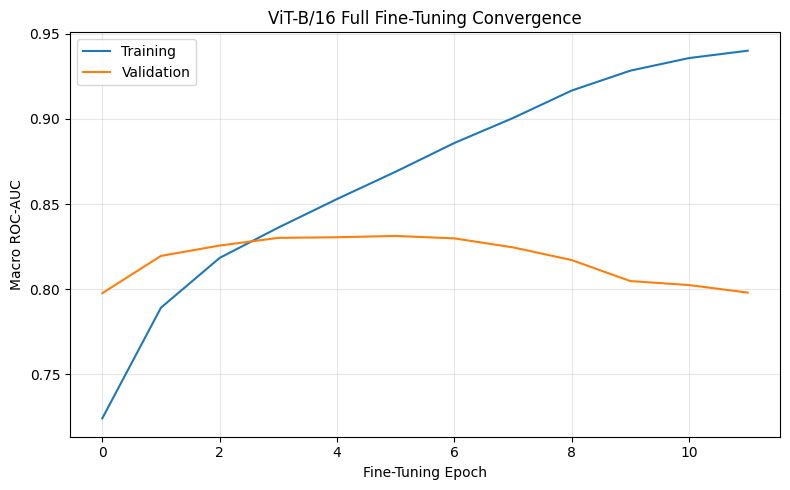

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['auc'], label='Training')
plt.plot(history.history['val_auc'], label='Validation')
plt.xlabel('Fine-Tuning Epoch')
plt.ylabel('Macro ROC-AUC')
plt.title('ViT-B/16 Full Fine-Tuning Convergence')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/vit_training_curve.png', dpi=300, bbox_inches='tight')
plt.show()

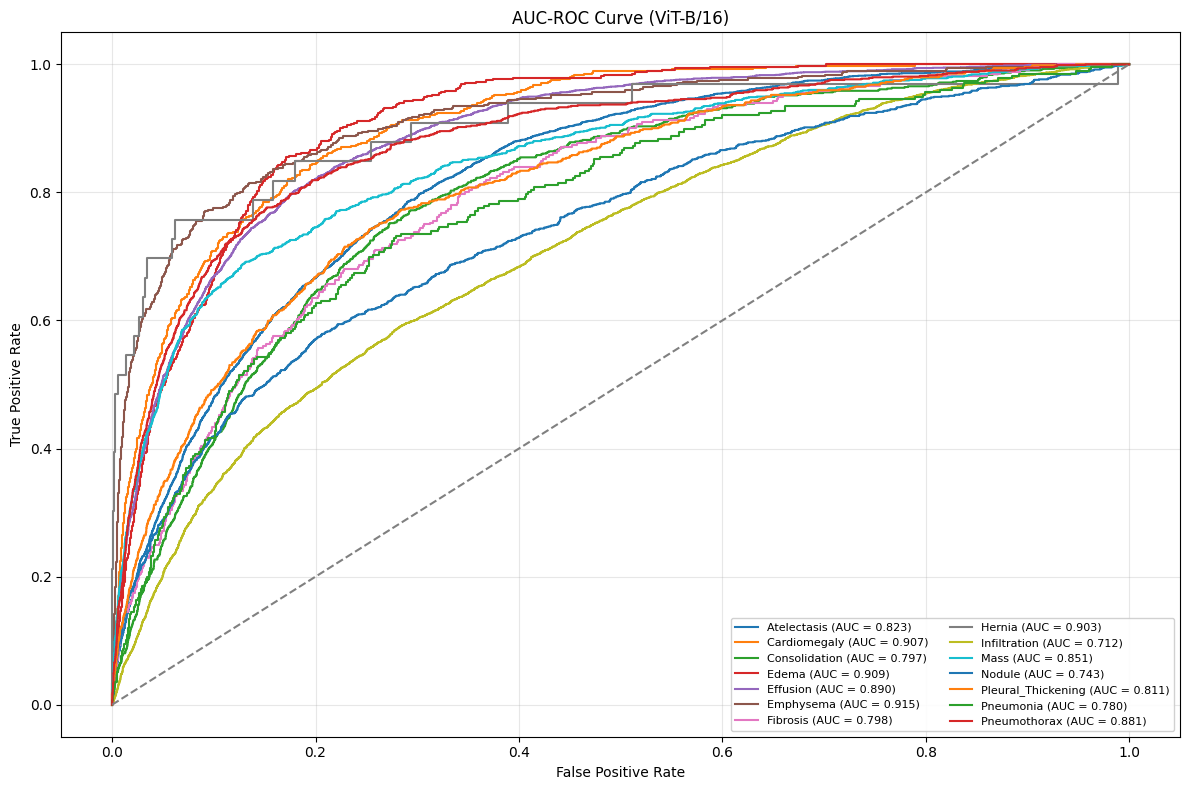

In [20]:
plt.figure(figsize=(12, 8))
for c, name in enumerate(disease_classes):
    fpr, tpr, _ = roc_curve(Y_test[:, c], test_probabilities[:, c])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('AUC-ROC Curve (ViT-B/16)')
plt.legend(loc='lower right', fontsize=8, ncol=2, framealpha=0.9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/vit_roc_curves.png', dpi=300, bbox_inches='tight')
plt.show()